# Forecast calibration and trading activity

The intermediate calculations were executed; this reading edition adds retrospective explanation. Historical evaluation blocks were reused; they are not fresh holdouts.

Read the saved outputs without executing this notebook. Original code cells, their metadata, execution counts and outputs are preserved. This package supplies selected scientific evidence and context; the code retains its original source environment and frozen-input dependencies. It is not a standalone reproduction environment. See the [notebook index](README.md).

The saved source calls the intermediate scientific modules. Inspect the [method reference](../method-reference/calibration-covariance/README.md) for their numerical definitions and unsupplied dependencies.


## Research question: Calibration and trading activity


Trading measures supplied the original study's strongest company-level improvements, but much of the apparent gain concerned lower mean forecast error across companies. The calibration comparison (source label RI1) asks whether calibration explains that benefit; the trading-activity comparison (RI2) asks whether activity retains distinct information once timing and recent risk are controlled.


Read from purpose through methods, checks, results and interpretation. The source calculation uses `quiet_index_500.expansions.forecasts` and displays its saved numerical evidence and figures. The saved numerical outputs and retrospective explanation should be read together.


## 1. Purpose and hypotheses


RI1 proposes that added characteristics partly compensate for a stale or misspecified overall risk forecast. RI2 proposes that activity captures information arrival, attention or a changing risk environment. Neither explanation follows simply from a lower historical loss.

First compare a small calibration sequence. Then add activity to the prespecified calibrated baseline. Separate risk-level accuracy, company differences and ranking, and retain the specified reference model for subsequent semiconductor comparisons, regardless of which historical comparison wins.


## 2. Inputs, comparison definitions and historical bridge


Use the bundled prepared feature panel and fixed following-quarter target. Preserve the study plan's development and historical evaluation blocks. All paired models are scored on common company/quarter observations.

Build only the narrow bridge needed to reconcile the original log-volatility MSE comparisons with this study's models. The original study used different controls and training conventions; its reported percentage improvement is not directly interchangeable with the new variance QLIKE endpoint.


In [1]:
from pathlib import Path
import os
import sys

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
assert (root / "src" / "quiet_index_500").exists(), "Run from the repository or notebooks directory."
os.environ.setdefault("MPLCONFIGDIR", "/private/tmp/quiet-index-500-matplotlib")
if str(root / "src") not in sys.path:
    sys.path.insert(0, str(root / "src"))

import pandas as pd
from IPython.display import Image, display
from quiet_index_500.expansions import forecasts as component
from quiet_index_500.expansions import common, settings as cfg

component_id = "06"

def show_table(name, columns=None, query=None, n=12):
    frame = common.read(component_id, name)
    if query is not None:
        frame = frame.query(query)
    if columns is not None:
        frame = frame[columns]
    print(f"{name}.csv — showing {min(n, len(frame))} of {len(frame)} rows")
    display(frame.head(n))

def show_figure(name):
    display(Image(filename=str(cfg.result_root / component_id / (name + ".png"))))

def show_inventory():
    records = []
    for path in sorted((cfg.result_root / component_id).glob("*.csv")):
        records.append({"table": path.name, "rows": len(pd.read_csv(path)),
                        "manifest": path.with_suffix(".manifest.json").name})
    display(pd.DataFrame(records))

for variant, controls in [("main", "sector"), ("window252", "sector"),
                          ("equity_shock", "sector"), ("main", "industry_group")]:
    component.run(variant, controls)
print("Component calculations and figures saved. Interpretation reserved for the staged review.")


Component calculations and figures saved. Interpretation reserved for the staged review.


In [2]:
# Evidence for analysis: reconcile_original_and_new_forecast_definitions
show_table("original_bridge_summary", n=20)
print("Bridge retains original raw-volatility degrees correction, unweighted pooled fit, eight-quarter minimum and log-volatility MSE averaging.")
print("New comparisons use quarter weights, 2018–2022 initial development, n−1 variance and primary variance QLIKE.")


original_bridge_summary.csv — showing 9 of 9 rows


,comparison,block,mean_original_relative_mse_improvement,quarters
0,old_amihud,development,0.012171,12
1,old_amihud,historical_late,0.027580,6
2,old_amihud,historical_validation,0.010100,8
3,old_dollar_volume,development,0.040268,12
4,old_dollar_volume,historical_late,0.087816,6
5,old_dollar_volume,historical_validation,0.027308,8
6,old_semiconductor,development,0.001526,12
7,old_semiconductor,historical_late,-0.003626,6
8,old_semiconductor,historical_validation,0.010432,8


Bridge retains original raw-volatility degrees correction, unweighted pooled fit, eight-quarter minimum and log-volatility MSE averaging.
New comparisons use quarter weights, 2018–2022 initial development, n−1 variance and primary variance QLIKE.


**Interpretation.** The narrow original-style bridge reproduces validation/late mean quarterly log-volatility MSE gains: signed SMH 1.0432% / −0.3626%, dollar volume 2.7308% / 8.7816%, Amihud 1.0100% / 2.7580%. Its pooled fit, masks, raw-volatility predictor and unsmeared scores differ from the new quarter-weighted QLIKE comparison. See bridge summary.


## 3. Analysis — chronological fitting and scoring


At each formation use only earlier completed outcome quarters available by that formation. Start with 2018–2022 development outcomes and then expand chronologically. Give quarters equal total training weight and companies equal weight within quarter.

Fit log future variance. Learn scaling, category handling and the residual-based exponential adjustment from training data only. A fixed model recipe can be refitted as earlier outcomes become available.


In [3]:
# Evidence for analysis: build_expanding_training_and_forecast_records
show_table("eligibility_main_sector", n=20)


eligibility_main_sector.csv — showing 14 of 14 rows


,formation_date,variant,controls,companies,possible_companies,represented_snapshot_weight,training_quarters,training_rows,latest_training_outcome_end,latest_training_outcome_last_session,latest_training_formation
0,2022-12-30,main,sector,484,500,0.985061,20,9368,2022-12-31,2022-12-30,2022-09-30
1,2023-03-31,main,sector,486,500,0.987063,21,9852,2023-03-31,2023-03-31,2022-12-30
2,2023-06-30,main,sector,486,500,0.987063,22,10338,2023-06-30,2023-06-30,2023-03-31
3,2023-09-29,main,sector,487,500,0.988333,23,10824,2023-09-30,2023-09-29,2023-06-30
4,2023-12-29,main,sector,487,500,0.988333,24,11311,2023-12-31,2023-12-29,2023-09-29
5,2024-03-28,main,sector,487,500,0.988333,25,11798,2024-03-31,2024-03-28,2023-12-29
6,2024-06-28,main,sector,487,500,0.988333,26,12285,2024-06-30,2024-06-28,2024-03-28
7,2024-09-30,main,sector,488,500,0.988781,27,12772,2024-09-30,2024-09-30,2024-06-28
8,2024-12-31,main,sector,489,500,0.989295,28,13260,2024-12-31,2024-12-31,2024-09-30
9,2025-03-31,main,sector,489,500,0.989295,29,13749,2025-03-31,2025-03-31,2024-12-31


### 3.1 Scoring quantities and their meanings


The primary loss is variance `QLIKE = V/Vhat − log(V/Vhat) − 1`; a positive baseline-minus-extension difference favors the extension. Average companies within quarter, then quarters equally.

Also report MSE of log volatility. Within a quarter its prediction errors satisfy `MSE = mean(error)^2 + mean((error − mean(error))^2)`. This centered-error term uses the mean squared deviation, not the n−1 sample variance used for risk estimation. Future-quarter centering is an accounting diagnostic, never a forecast correction. Spearman correlation measures ranking separately.


In [4]:
# Evidence for analysis: score_paired_risk_forecasts
show_table("quarters_main_sector", columns=["formation_date", "block", "comparison", "companies", "baseline_loss", "extension_loss", "improvement", "baseline_logvol_mse", "extension_logvol_mse", "baseline_spearman", "extension_spearman"], n=16)


quarters_main_sector.csv — showing 16 of 112 rows


,formation_date,block,comparison,companies,baseline_loss,extension_loss,improvement,baseline_logvol_mse,extension_logvol_mse,baseline_spearman,extension_spearman
0,2022-12-30,historical_validation,RI1_calibration,484,0.141392,0.146901,-0.005509,0.081606,0.086970,0.619654,0.652952
1,2022-12-30,historical_validation,calibration_log_shape,484,0.141392,0.147452,-0.006060,0.081606,0.084695,0.619654,0.635251
2,2022-12-30,historical_validation,calibration_recency,484,0.147452,0.146901,0.000551,0.084695,0.086970,0.635251,0.652952
3,2022-12-30,historical_validation,RI2_activity,484,0.146901,0.141415,0.005486,0.086970,0.083205,0.652952,0.659901
4,2022-12-30,historical_validation,activity252,484,0.146901,0.144169,0.002732,0.086970,0.085202,0.652952,0.657666
5,2022-12-30,historical_validation,amihud60,484,0.146901,0.139552,0.007349,0.086970,0.081929,0.652952,0.659790
6,2022-12-30,historical_validation,amihud252,484,0.146901,0.136773,0.010128,0.086970,0.079155,0.652952,0.657029
7,2022-12-30,historical_validation,own_history_activity,484,0.146901,0.151636,-0.004735,0.086970,0.090412,0.652952,0.646964
8,2023-03-31,historical_validation,RI1_calibration,486,0.163579,0.160167,0.003412,0.099821,0.096548,0.708538,0.719119
9,2023-03-31,historical_validation,calibration_log_shape,486,0.163579,0.169567,-0.005988,0.099821,0.102220,0.708538,0.715305


## 4. Calibration sequence (RI1)


All three models share log positive issuer capitalization, sector indicators, the six standard-factor loadings, the joint rate loading, signed rate-aware SMH loading and own momentum.

| Model | Risk predictors | Role |
|---|---|---|
| C0 | Raw trailing standard-factor residual volatility | Reference shape |
| C_log | Log trailing residual variance | Scale-transformation diagnostic |
| C | C_log plus log recent-60-session/trailing variance | Prespecified calibrated baseline |

The primary RI1 comparison is C0 to C. C_log separates the transformation from recency; it is a supporting comparison. All models predict the same log future variance.


In [5]:
# Evidence for analysis: compare_calibration_sequence
show_table("summary_main_sector", query="comparison in ['RI1_calibration', 'calibration_log_shape', 'calibration_recency']", n=20)


summary_main_sector.csv — showing 6 of 6 rows


,comparison,variant,controls,block,effect,ci_low,ci_high,p_two_sided,quarters,calendar_quarters,missing_quarters,baseline_loss,extension_loss,relative_improvement
0,RI1_calibration,main,sector,historical_late,0.038374,0.017406,0.060615,0.0005,6,6,0,0.192961,0.154588,0.198866
1,RI1_calibration,main,sector,historical_validation,0.005651,0.002660,0.008642,0.0005,8,8,0,0.168731,0.163080,0.033491
10,calibration_log_shape,main,sector,historical_late,0.016355,0.009509,0.023833,0.0005,6,6,0,0.192961,0.176607,0.084757
11,calibration_log_shape,main,sector,historical_validation,-0.003853,-0.006078,-0.001629,0.0005,8,8,0,0.168731,0.172584,-0.022837
12,calibration_recency,main,sector,historical_late,0.022019,0.007256,0.037665,0.0005,6,6,0,0.176607,0.154588,0.124676
13,calibration_recency,main,sector,historical_validation,0.009504,0.004289,0.014720,0.0005,8,8,0,0.172584,0.163080,0.055071


**Keep the two design changes separate.** Replacing raw trailing volatility with log variance changes functional form. Adding recent/trailing variance changes information recency. Their saved validation signs differ; the combined RI1 result cannot identify one explanation by itself.


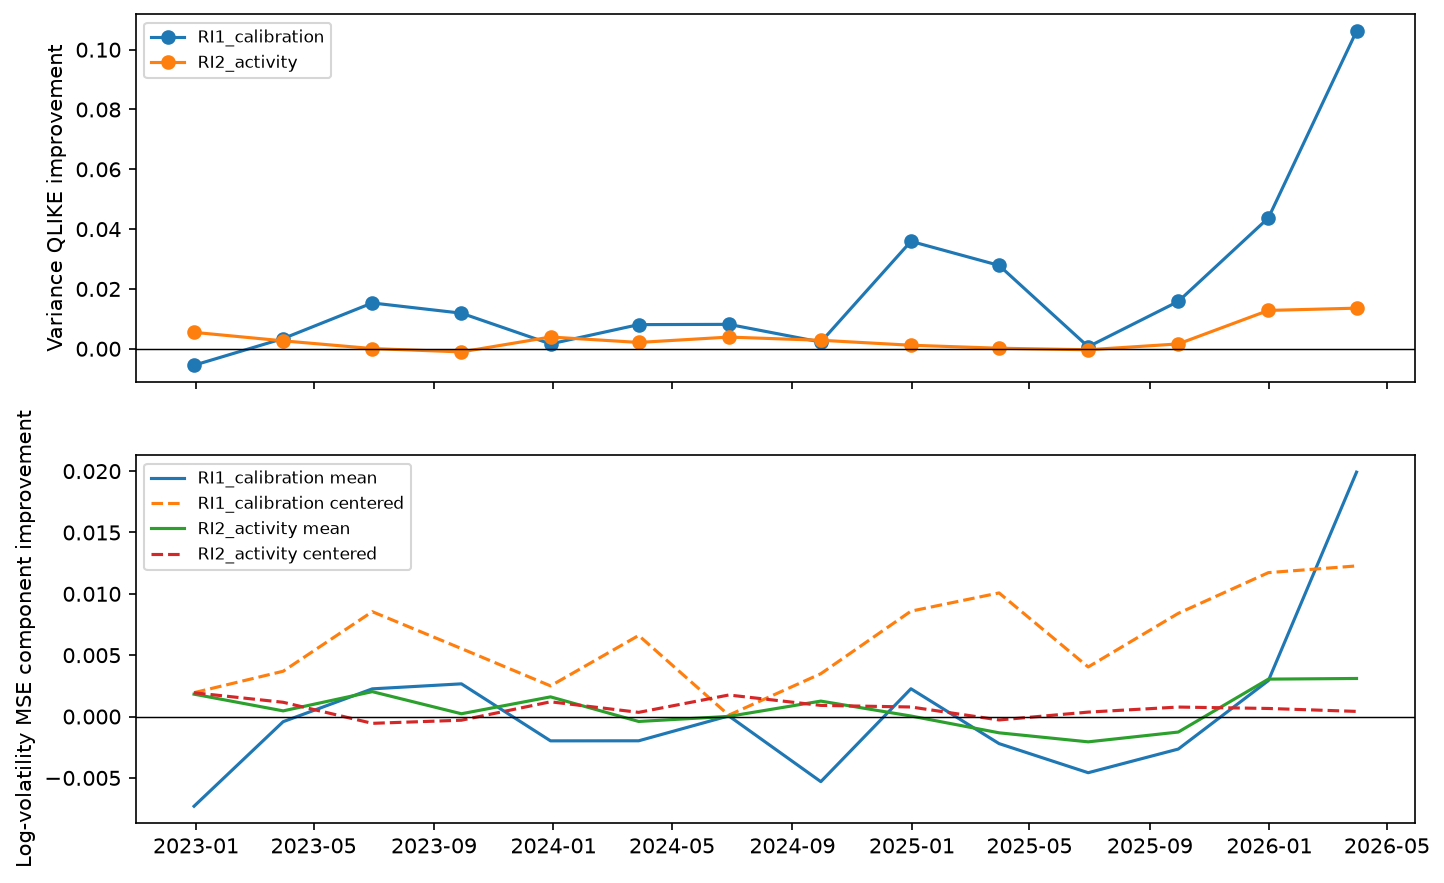

In [6]:
# Evidence for visualization: plot_calibration_scores_and_error_components
show_figure("calibration_and_error_components")


**Interpretation.** C0 → C improves QLIKE 0.005651 / 0.038374 (validation/late), but shape alone worsens validation −0.003853 while recency helps 0.009504. Main RI1 wins 7/8 and 6/6 quarters. In validation the squared mean log-volatility error worsens while centered dispersion falls; calibration is not only a common-level repair. Component means and reading note explain the distinction.


## 5. Trading activity beyond calibration (RI2)


The primary RI2 comparison adds log 60-session median dollar volume to C. Assess Amihud separately before any semiconductor-by-liquidity interaction. The question is whether activity retains information once the baseline already includes recent risk.


In [7]:
# Evidence for analysis: compare_activity_and_liquidity_main_effects
show_table("summary_main_sector", query="comparison in ['RI2_activity', 'amihud252']", n=20)


summary_main_sector.csv — showing 4 of 4 rows


,comparison,variant,controls,block,effect,ci_low,ci_high,p_two_sided,quarters,calendar_quarters,missing_quarters,baseline_loss,extension_loss,relative_improvement
2,RI2_activity,main,sector,historical_late,0.004838,0.000653,0.009264,0.000500,6,6,0,0.154588,0.149749,0.031299
3,RI2_activity,main,sector,historical_validation,0.002491,0.001331,0.003652,0.000500,8,8,0,0.163080,0.160589,0.015277
6,amihud252,main,sector,historical_late,0.002934,-0.000736,0.006979,0.163418,6,6,0,0.154588,0.151654,0.018978
7,amihud252,main,sector,historical_validation,0.002937,0.000607,0.005266,0.000500,8,8,0,0.163080,0.160144,0.018007


### 5.1 Equal horizons and activity relative to own history


Compare dollar volume and Amihud at both 60 and 252 sessions, with their specified eligibility rules. Inspect the supporting 60/prior-192-session activity ratio to distinguish trading scale from a recent change.

These comparisons discriminate between measurement recency and liquidity/activity mechanisms. They are supporting analyses, not candidates from which to choose the best-performing primary recipe.


In [8]:
# Evidence for analysis: compare_matched_horizons_and_own_history_activity
show_table("summary_main_sector", query="comparison in ['RI2_activity', 'activity252', 'amihud60', 'amihud252', 'own_history_activity']", n=20)


summary_main_sector.csv — showing 10 of 10 rows


,comparison,variant,controls,block,effect,ci_low,ci_high,p_two_sided,quarters,calendar_quarters,missing_quarters,baseline_loss,extension_loss,relative_improvement
2,RI2_activity,main,sector,historical_late,0.004838,0.000653,0.009264,0.000500,6,6,0,0.154588,0.149749,0.031299
3,RI2_activity,main,sector,historical_validation,0.002491,0.001331,0.003652,0.000500,8,8,0,0.163080,0.160589,0.015277
4,activity252,main,sector,historical_late,0.003778,-0.000256,0.008087,0.163418,6,6,0,0.154588,0.150810,0.024440
5,activity252,main,sector,historical_validation,0.002165,0.001242,0.003087,0.000500,8,8,0,0.163080,0.160915,0.013275
6,amihud252,main,sector,historical_late,0.002934,-0.000736,0.006979,0.163418,6,6,0,0.154588,0.151654,0.018978
7,amihud252,main,sector,historical_validation,0.002937,0.000607,0.005266,0.000500,8,8,0,0.163080,0.160144,0.018007
8,amihud60,main,sector,historical_late,0.002117,-0.000626,0.005004,0.163418,6,6,0,0.154588,0.152471,0.013694
9,amihud60,main,sector,historical_validation,0.000152,-0.002305,0.002609,0.752624,8,8,0,0.163080,0.162928,0.000931
14,own_history_activity,main,sector,historical_late,-0.000662,-0.000767,-0.000579,0.000500,6,6,0,0.154588,0.155250,-0.004285
15,own_history_activity,main,sector,historical_validation,-0.000800,-0.001774,0.000173,0.199400,8,8,0,0.163080,0.163881,-0.004909


**Read all horizons.** Dollar-volume60, dollar-volume252, Amihud60, Amihud252 and own-history activity are planned supporting comparisons, not a search from which the best historical horizon becomes the primary model.


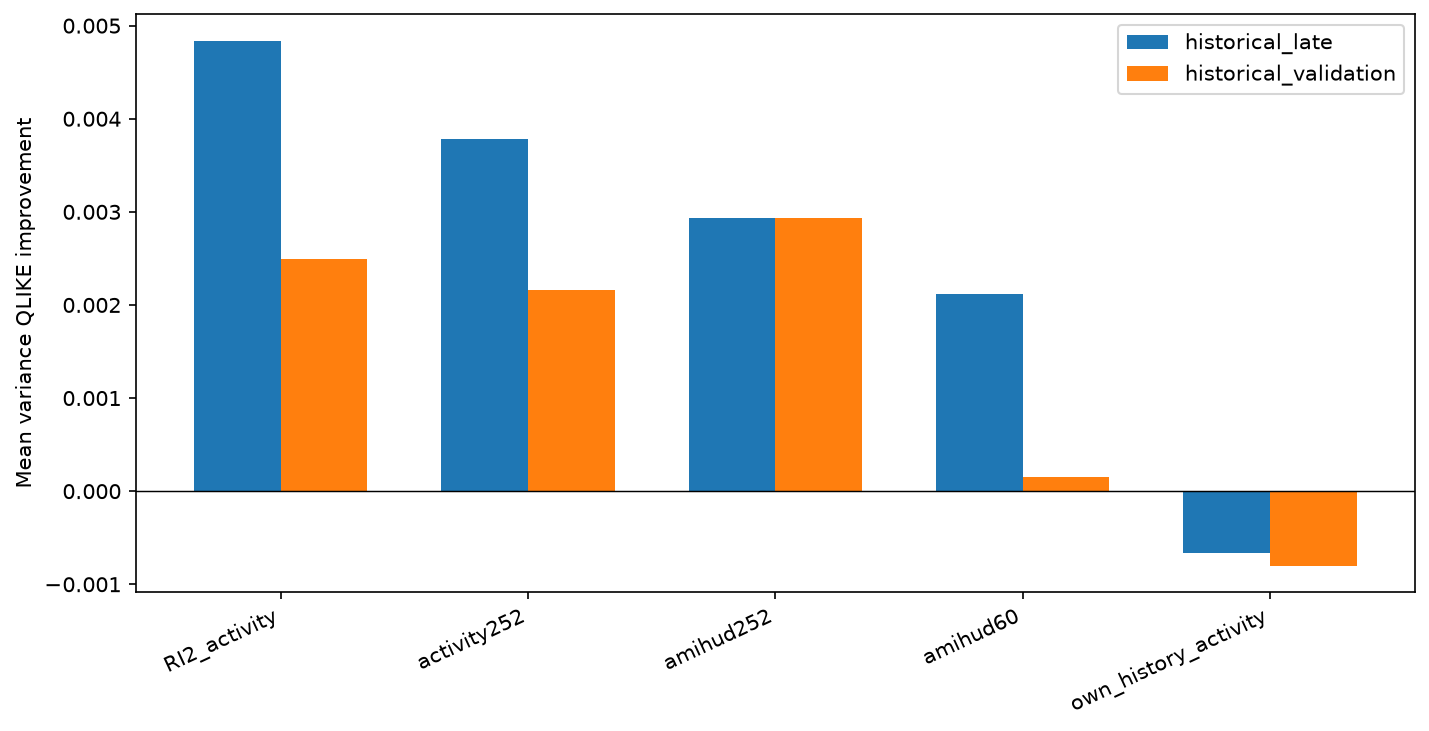

In [9]:
# Evidence for visualization: plot_activity_evidence
show_figure("activity_horizon_comparisons")


**Interpretation.** Activity60 retains positive main QLIKE gains 0.002491 / 0.004838 after C. Longer activity and Amihud comparisons are weaker late, and own-history activity is adverse in both blocks. This supports additional historical activity information, with no unique liquidity/attention interpretation. The horizon figure includes all prespecified comparisons.


## 6. Sensitivities and uncertainty


Repeat the specified 252-session exposure window, equity-only SMH definition and industry-group-control sensitivity without choosing new windows from outcomes. Keep sparse-group handling fixed. Preserve the entire company cross-section when resampling quarters.

Use the planned 2,000-draw, four-quarter moving-block bootstrap with seed 20261014 and document boundary handling. Any intervals condition on saved first-stage estimates and forecasts. The source synthesis assembles the comparison family; the saved identifiers retain that mapping.


In [10]:
# Evidence for validation: summarize_calibration_activity_sensitivities
for suffix in ["main_sector", "window252_sector", "equity_shock_sector", "main_industry_group"]:
    show_table("summary_" + suffix, query="comparison in ['RI1_calibration', 'RI2_activity']", n=8)


summary_main_sector.csv — showing 4 of 4 rows


,comparison,variant,controls,block,effect,ci_low,ci_high,p_two_sided,quarters,calendar_quarters,missing_quarters,baseline_loss,extension_loss,relative_improvement
0,RI1_calibration,main,sector,historical_late,0.038374,0.017406,0.060615,0.0005,6,6,0,0.192961,0.154588,0.198866
1,RI1_calibration,main,sector,historical_validation,0.005651,0.002660,0.008642,0.0005,8,8,0,0.168731,0.163080,0.033491
2,RI2_activity,main,sector,historical_late,0.004838,0.000653,0.009264,0.0005,6,6,0,0.154588,0.149749,0.031299
3,RI2_activity,main,sector,historical_validation,0.002491,0.001331,0.003652,0.0005,8,8,0,0.163080,0.160589,0.015277


summary_window252_sector.csv — showing 4 of 4 rows


,comparison,variant,controls,block,effect,ci_low,ci_high,p_two_sided,quarters,calendar_quarters,missing_quarters,baseline_loss,extension_loss,relative_improvement
0,RI1_calibration,window252,sector,historical_late,0.024113,0.011572,0.037914,0.000500,6,6,0,0.173646,0.149533,0.138864
1,RI1_calibration,window252,sector,historical_validation,0.004060,0.000604,0.007517,0.034483,8,8,0,0.169840,0.165780,0.023906
2,RI2_activity,window252,sector,historical_late,0.004077,0.000227,0.008200,0.057971,6,6,0,0.149533,0.145456,0.027268
3,RI2_activity,window252,sector,historical_validation,0.002755,0.002030,0.003481,0.000500,8,8,0,0.165780,0.163024,0.016621


summary_equity_shock_sector.csv — showing 4 of 4 rows


,comparison,variant,controls,block,effect,ci_low,ci_high,p_two_sided,quarters,calendar_quarters,missing_quarters,baseline_loss,extension_loss,relative_improvement
0,RI1_calibration,equity_shock,sector,historical_late,0.038393,0.017420,0.060637,0.0005,6,6,0,0.192974,0.154581,0.198955
1,RI1_calibration,equity_shock,sector,historical_validation,0.005647,0.002665,0.008628,0.0005,8,8,0,0.168683,0.163037,0.033474
2,RI2_activity,equity_shock,sector,historical_late,0.004826,0.000626,0.009252,0.0005,6,6,0,0.154581,0.149755,0.031218
3,RI2_activity,equity_shock,sector,historical_validation,0.002478,0.001321,0.003634,0.0005,8,8,0,0.163037,0.160559,0.015198


summary_main_industry_group.csv — showing 4 of 4 rows


,comparison,variant,controls,block,effect,ci_low,ci_high,p_two_sided,quarters,calendar_quarters,missing_quarters,baseline_loss,extension_loss,relative_improvement
0,RI1_calibration,main,industry_group,historical_late,0.036273,0.015995,0.057683,0.0005,6,6,0,0.191732,0.155459,0.189186
1,RI1_calibration,main,industry_group,historical_validation,0.006562,0.003089,0.010034,0.0005,8,8,0,0.170074,0.163512,0.038583
2,RI2_activity,main,industry_group,historical_late,0.005401,0.000903,0.009945,0.0005,6,6,0,0.155459,0.150058,0.034744
3,RI2_activity,main,industry_group,historical_validation,0.002384,0.001367,0.003400,0.0005,8,8,0,0.163512,0.161128,0.014579


## 7. Results — calibration, activity and interpretation


### Retrospective findings and explanation

[Reading notebook](forecast-calibration-and-trading-activity.ipynb)

**The design.** All recipes share log issuer capitalization, sector indicators, six standard-factor loadings, joint rate loading, signed rate-aware lambda and own momentum. **C0** adds raw trailing standard-factor residual volatility. **C_log** replaces that predictor with log trailing residual variance. **C** additionally includes log recent-60/trailing variance. All predict the same log future variance. Changing predictor shape is not the same operation as adding recent information. C0 → C is primary RI1; C0 → C_log and C_log → C diagnose the two pieces. Primary RI2 adds log 60-session median dollar volume to C.

The full recipe sequence uses one intersection sample, rather than allowing the C0 row to include companies unavailable to the activity models. Main scored quarters contain **484–488 companies** in validation and **489–494** late, representing **98.51%–98.88%** and **98.93%–99.44%** of fixed snapshot weight, respectively. Training begins with 20 completed development quarters and expands chronologically. These are per-quarter ranges from the cited quarter/coverage tables, not total unique companies or historical index coverage.

| Main comparison | 2023–2024: absolute QLIKE gain | 2025–2026 Q2: absolute QLIKE gain | Percentage reduction in mean loss, validation / late |
|---|---:|---:|---:|
| RI1: C0 → C | 0.005651 [0.002660, 0.008642] | 0.038374 [0.017406, 0.060615] | 3.35% / 19.89% |
| Shape only: C0 → C_log | −0.003853 [−0.006078, −0.001629] | 0.016355 [0.009509, 0.023833] | −2.28% / 8.48% |
| Recent risk: C_log → C | 0.009504 [0.004289, 0.014720] | 0.022019 [0.007256, 0.037665] | 5.51% / 12.47% |
| RI2: C → dollar-volume60 | 0.002491 [0.001331, 0.003652] | 0.004838 [0.000653, 0.009264] | 1.53% / 3.13% |

*Source: summary_main_sector.csv, `variant=main`, `controls=sector`, named `comparison` and `block`; brackets are saved conditional 95% bootstrap intervals. C0/C_log/C are fitted recipes, so adjacent percentage reductions do not add. Absolute gains along that path do add on the shared sample.*

A concrete RI1 late-block calculation is `(0.192961393145 − 0.154587865077)/0.192961393145 = 19.8866%`. It compares mean QLIKE, not residual variance units or a mean quarterly percentage. Calibration improves seven of eight validation quarters and all six late quarters. Activity improves seven of eight and five of six respectively. The exceptions remain visible in the quarter figure. The largest late calibration gain does not demonstrate a universal gain of the same size.

![Calibration, activity and horizon comparisons](assets/forecast-calibration-and-trading-activity-calibration_horizons.png)

*Source: 06 main summary, all eight comparisons and both blocks. Bars show absolute QLIKE gain; whiskers are saved conditional 95% intervals, with no new uncertainty calculation. Main 504-session rate-aware exposures and sector controls, 484–494 companies per quarter. SVG. The first two comparisons isolate predictor shape and recency; they should not be read as independent tests of one universal mechanism.*

**What does calibration repair?** The diagnostic log-volatility errors use the **smeared variance predictions**: error is `0.5 log(V) − 0.5 log(Vhat)`. Within a quarter, MSE equals squared mean error plus centered mean squared error. Future-quarter centering is an accounting identity, not a permissible formation-time correction. In validation, C0 → C lowers mean log-volatility MSE from **0.089787 to 0.087236** while **raising squared mean error from 0.025928 to 0.027430** and lowering centered error from **0.063860 to 0.059805**. Average quarterly Spearman rank correlation rises **0.6745 to 0.7016**. In the late block both components improve: squared mean error **0.010592 to 0.007980**, centered error **0.067617 to 0.058431**, and rank correlation **0.7287 to 0.7519**. These exact equal-quarter means are in error_component_means.csv, `comparison=RI1_calibration`.

![Mean and centered log-volatility errors](assets/forecast-calibration-and-trading-activity-calibration_error_components.png)

*Each bar is baseline minus extension component, equal-quarter means over the same 8/6 blocks and company samples as 06. A negative mean-error bar in validation coexists with a positive total gain. These are log-volatility MSE components, on a separate scale from QLIKE. Source: quarterly component columns. SVG. No component is described as a share of QLIKE.*

This source evidence rules out the blanket explanation “all calibration improvement is a common level correction.” It also does not prove a company-specific causal mechanism. Calibration changes shape and recent information jointly; centered dispersion and rank gains are descriptive consequences on saved predictions. Later integration performs its own matched 14-quarter/28-model-quarter error accounting. That later result is not an output of this source notebook and must not be backdated into its design.

**Activity survives, with qualifications.** The main 60-session activity increment is positive in both blocks after calibration. But equal-horizon comparisons complicate a pure liquidity account. Dollar-volume252 gains **0.002165 / 0.003778**, Amihud252 **0.002937 / 0.002934**, and Amihud60 **0.000152 / 0.002117** in validation/late. The late intervals for these three all cross zero; Amihud60's validation interval also crosses zero. The own-history activity ratio is adverse, **−0.000800 / −0.000662**, with the late interval entirely negative. These are the named rows of the same main summary. A difference between a significant and nonsignificant increment is not itself a tested difference between increments.

Main RI1/RI2 effects remain positive under equity-only shocks and industry-group controls. Shorter-window RI1 gains shrink to **0.004060 / 0.024113** and RI2 to **0.002755 / 0.004077**; the saved late RI2 two-sided p-value is **0.05797**, so “robust in sign” should not be inflated to uniformly strong uncertainty evidence. See 252-session summary, equity-only summary and industry-group summary, corresponding primary rows.

The narrow original bridge deliberately restores original-style masks, raw-volatility predictor, pooled-row fitting and no smearing. It reproduces original-style mean quarterly log-volatility MSE percentage gains for signed SMH **1.0432% / −0.3626%**, dollar volume **2.7308% / 8.7816%**, and Amihud **1.0100% / 2.7580%** in validation/late. Those figures answer a different question from the QLIKE table above. Their purpose is reconciliation, not to make a new 3.13% QLIKE gain appear a decline from 8.78% under an interchangeable metric.

**What follows.** A stronger baseline is necessary before giving a semiconductor mechanism credit. C remains the prespecified recipe regardless of historical winners. The source investigation then adds activity, liquidity and market-downside controls before testing conditional semiconductor exposure. The remaining activity signal could reflect information arrival, attention, risk persistence or proxy overlap; these saved comparisons cannot separate those causal explanations.


## Takeaways and limits


**Interpretation.** Both calibration and incremental activity matter, but neither identifies its causal mechanism. The source mean/centered-error accounting uses smeared diagnostic predictions and a different metric from QLIKE. Later integration error accounting is later reconciliation. C remains the specified reference model for the subsequent comparisons; it is not selected from historical winners.


## Related evidence

The [findings and synthesis](../FINDINGS.md) reconcile these results with the other company and portfolio comparisons. Source comparison identifiers remain in the saved outputs for traceability.


The subsequent semiconductor comparisons retain the specified C recipe and the same activity definitions and chronological scoring conventions. The baseline is not replaced by the best-performing historical horizon.


In [11]:
# Evidence for artifact: save_notebook_evidence
show_inventory()


,table,rows,manifest
0,coefficients_equity_shock_sector.csv,2618,coefficients_equity_shock_sector.manifest.json
1,coefficients_main_industry_group.csv,4186,coefficients_main_industry_group.manifest.json
2,coefficients_main_sector.csv,2618,coefficients_main_sector.manifest.json
3,coefficients_window252_sector.csv,2618,coefficients_window252_sector.manifest.json
4,eligibility_equity_shock_sector.csv,14,eligibility_equity_shock_sector.manifest.json
5,eligibility_main_industry_group.csv,14,eligibility_main_industry_group.manifest.json
6,eligibility_main_sector.csv,14,eligibility_main_sector.manifest.json
7,eligibility_window252_sector.csv,14,eligibility_window252_sector.manifest.json
8,original_bridge_quarters.csv,78,original_bridge_quarters.manifest.json
9,original_bridge_summary.csv,9,original_bridge_summary.manifest.json
